# Final Project: Cat and Dog Image Classification with Transfer Learning and Image Segmentation

This project implements an image classification model to distinguish between cats and dogs using transfer learning. A pre-trained convolutional neural network is used as a feature extractor, and a custom classification layer is trained for binary classification.

In addition, an image segmentation method is also applied.

## Import Libraries

The required libraries are imported. TensorFlow and Keras are used to build and train the deep learning model, TensorFlow Datasets is used to load the dataset, and Matplotlib is used for visualization.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers

## Dataset Loading

The Cats vs Dogs dataset was loaded using TensorFlow Datasets. The dataset contains 23,262 valid RGB images. The images belong to two classes: cats and dogs. An 80%-20% split was used to create training and testing datasets.

In [37]:
(ds_train, ds_test), ds_info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

class_names = ds_info.features["label"].names

print("Class names:", class_names)
print("Total valid images:", ds_info.splits["train"].num_examples)
print("Training images:", int(ds_info.splits["train"].num_examples * 0.8))
print("Testing images:", int(ds_info.splits["train"].num_examples * 0.2))

Class names: ['cat', 'dog']
Total valid images: 23262
Training images: 18609
Testing images: 4652


## Dataset Visualization

Several sample images are displayed to better understand the dataset. The images show significant variation in pose, scale, illumination, background, and object appearance. Such variability makes the classification task realistic and suitable for evaluating deep learning models.

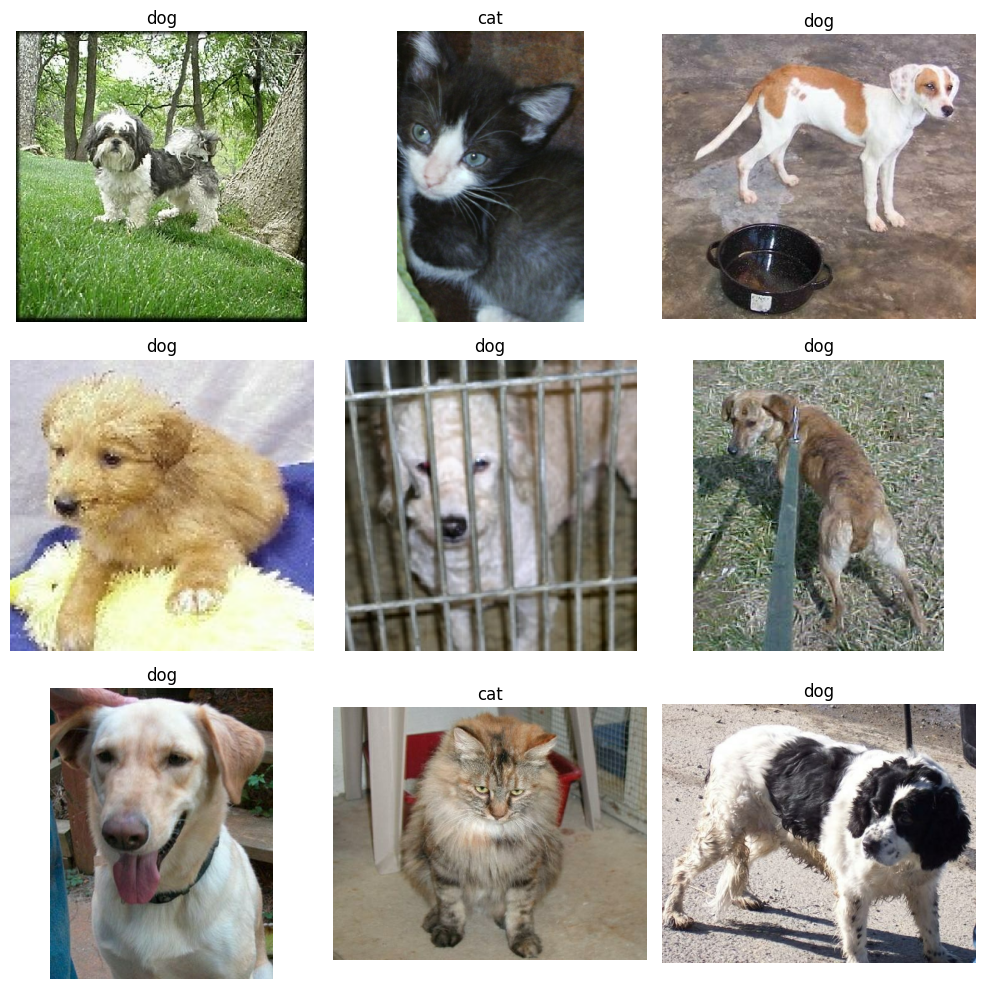

In [38]:
plt.figure(figsize=(10, 10))

for i, (image, label) in enumerate(ds_train.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Data Preprocessing

The original images have different resolutions and aspect ratios. Therefore, all images are resized to 160×160 pixels to provide a consistent input size for the neural network. The MobileNetV2 preprocessing function is then applied to normalize pixel values according to the requirements of the pre-trained model.

In [41]:
IMG_SIZE = 160
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

train_ds = (
    ds_train
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    ds_test
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

## Data Augmentation

Data augmentation is applied to the training images to improve generalization. Random flips, rotations, and zooms create slightly different versions of the same image, helping the model become more robust and reducing overfitting.

In [42]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

## Transfer Learning Model

MobileNetV2 is used as a pre-trained convolutional neural network. The model was originally trained on ImageNet and has already learned useful visual features such as edges, textures, shapes, and object parts.

The original ImageNet classification layer is removed and replaced with a custom binary classifier designed specifically for cat-versus-dog recognition. During training, the MobileNetV2 feature extractor remains frozen, while only the newly added classification layers are updated.

In [44]:
base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Model Compilation

The model is compiled using the Adam optimizer and binary cross-entropy loss function. Binary cross-entropy is appropriate because this is a binary classification problem with two classes: cat and dog.

In [45]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Model Training

The model is trained using transfer learning. Because MobileNetV2 already contains visual features learned from millions of images in the ImageNet dataset, only a small number of training epochs is required to achieve high classification accuracy.

In [46]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 641s 1s/step - accuracy: 0.8248 - loss: 0.3856 - val_accuracy: 0.9598 - val_loss: 0.1461
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 619s 1s/step - accuracy: 0.9385 - loss: 0.1675 - val_accuracy: 0.9718 - val_loss: 0.0941
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 605s 1s/step - accuracy: 0.9471 - loss: 0.1355 - val_accuracy: 0.9770 - val_loss: 0.0757
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 607s 1s/step - accuracy: 0.9535 - loss: 0.1195 - val_accuracy: 0.9798 - val_loss: 0.0665
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 606s 1s/step - accuracy: 0.9570 - loss: 0.1083 - val_accuracy: 0.9809 - val_loss: 0.0612


The model was trained for five epochs using transfer learning. The training accuracy increased from 82.48% to 95.70%, while the validation accuracy reached 98.09%. This shows that the pre-trained MobileNetV2 model successfully extracted useful visual features and allowed the classifier to distinguish between cats and dogs with high accuracy.

## Model Evaluation

The trained model is evaluated on the test dataset to measure its performance on unseen images. The model achieved a test accuracy of 98.09% and a test loss of 0.0612. These results indicate that the model generalizes very well to unseen images and is capable of accurately distinguishing between cats and dogs.

In [47]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

146/146 ━━━━━━━━━━━━━━━━━━━━ 120s 807ms/step - accuracy: 0.9809 - loss: 0.0612
Test Accuracy: 0.9808684587478638
Test Loss: 0.061204634606838226


## Training and Validation Curves

The evolution of accuracy and loss during training is visualized below. These curves help identify whether the model is learning effectively and whether overfitting is occurring.

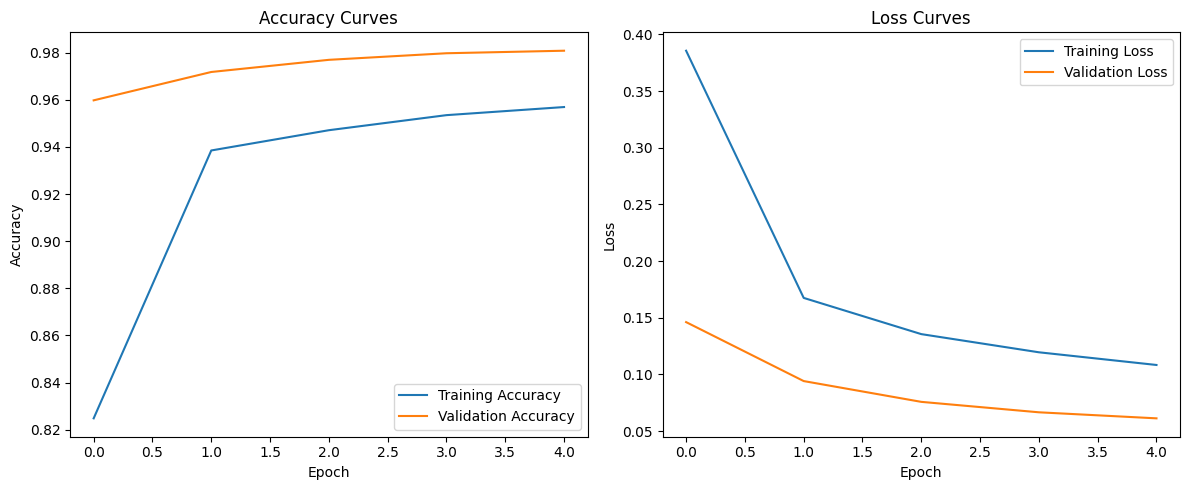

In [48]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()

plt.tight_layout()
plt.show()

The training accuracy increased from 82.48% in the first epoch to 95.70% in the final epoch. The validation accuracy also improved steadily, reaching 98.09%. At the same time, both training and validation losses decreased throughout the training process. These results indicate that the MobileNetV2 transfer learning model successfully learned discriminative features for cat and dog classification and generalized very well to unseen data. No significant signs of overfitting were observed during the training period.

## Prediction Examples
The trained model is used to predict the classes of unseen test images. The predicted label is compared with the true label to visually verify the classification performance.

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


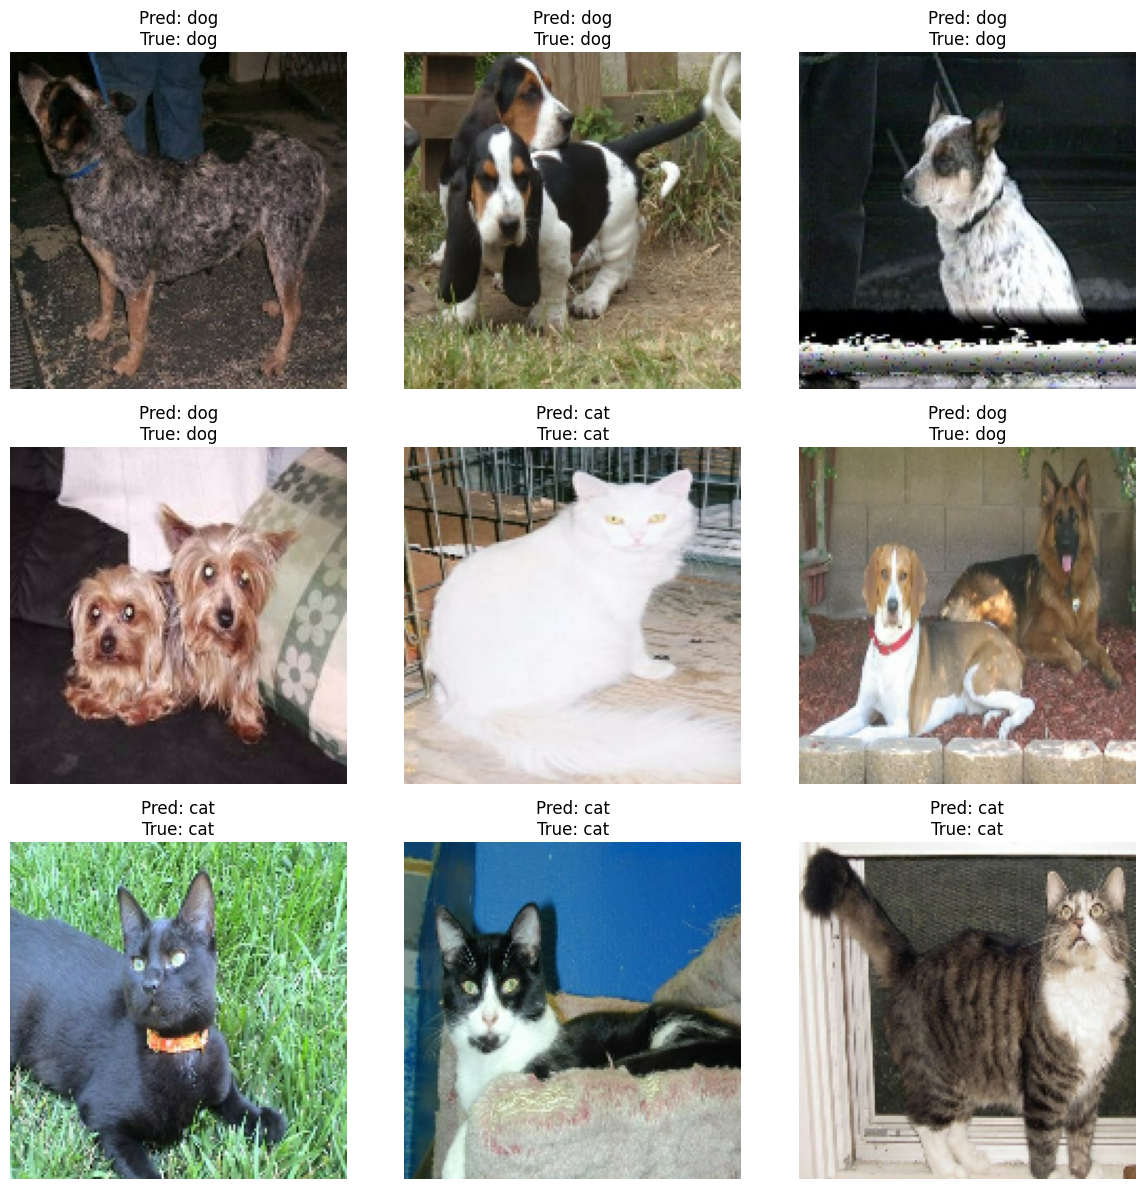

In [50]:
plt.figure(figsize=(12, 12))
for images, labels in test_ds.take(1):
    predictions = model.predict(images)
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow((images[i] + 1) / 2)
        predicted_label = "dog" if predictions[i] > 0.5 else "cat"
        true_label = "dog" if labels[i] == 1 else "cat"
        plt.title(
            f"Pred: {predicted_label}\nTrue: {true_label}"
        )
        plt.axis("off")
plt.tight_layout()
plt.show()

The prediction examples show that the model correctly classifies most cat and dog images. The high agreement between predicted and true labels is consistent with the test accuracy of approximately 98%, demonstrating strong classification performance.

## Image Segmentation Using SLIC Superpixels
Image segmentation is performed as an additional task. The SLIC (Simple Linear Iterative Clustering) algorithm groups neighboring pixels with similar colors into superpixels. This process divides an image into meaningful regions and simplifies image analysis.

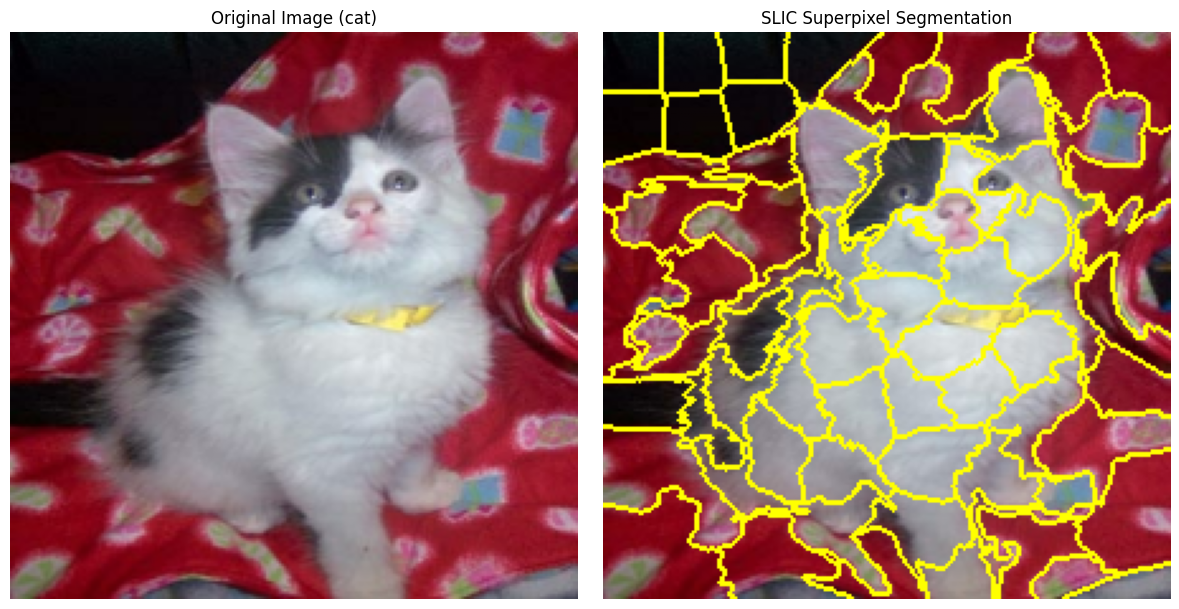

In [53]:
from skimage.segmentation import slic, mark_boundaries
from skimage.util import img_as_float

for image, label in ds_test.take(1):
    sample_image = image.numpy()
    sample_label = class_names[label.numpy()]

sample_resized = tf.image.resize(sample_image, (224, 224)).numpy().astype("uint8")

sample_float = img_as_float(sample_resized)

segments = slic(
    sample_float,
    n_segments=100,
    compactness=10,
    start_label=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(sample_resized)
axes[0].set_title(f"Original Image ({sample_label})")
axes[0].axis("off")

axes[1].imshow(mark_boundaries(sample_float, segments))
axes[1].set_title("SLIC Superpixel Segmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

The SLIC algorithm successfully divided the image into multiple superpixel regions. The boundaries generally follow changes in color and texture, allowing the cat and background to be represented by separate groups of regions.
Although SLIC does not directly perform object recognition, it effectively partitions the image into visually coherent regions. Such superpixel representations are commonly used as a preprocessing step in more advanced computer vision applications, including object detection and semantic segmentation.

## Conclusion

In this project, a transfer learning model was implemented to classify images of cats and dogs. MobileNetV2 was used as a pre-trained feature extractor, and a custom binary classification layer was trained for the final classification task.

The model achieved a test accuracy of approximately 98.09%, showing that transfer learning is highly effective for image classification problems. The training and validation curves showed stable learning behavior, with decreasing loss and increasing accuracy.

In addition, SLIC superpixel segmentation was applied to one image from the dataset. This demonstrated how an image can be divided into meaningful regions based on color and spatial similarity. Overall, the project shows the usefulness of deep learning and computer vision techniques for image understanding.